# Lab Sheet-III

$y''=f(x,y)$ methods. Starting values from RK4 on the system $(y, y')$.

## Q1. Numerov, linear

$y''=-y$, $y(0)=0$, $y'(0)=1$, exact $\sin x$  
$y_{n+1}-2y_n+y_{n-1}=\frac{h^2}{12}(f_{n+1}+10f_n+f_{n-1})$, with $f=-y$:  
$y_{n+1}=\dfrac{2(1-\frac{5h^2}{12})y_n-(1+\frac{h^2}{12})y_{n-1}}{1+\frac{h^2}{12}}$

--- h = 0.1 ---
     x         y num         sin x       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.10    0.09983333    0.09983342    8.3313e-08
  0.20    0.19866916    0.19866933    1.6621e-07
  0.30    0.29551996    0.29552021    2.4827e-07
  0.40    0.38941801    0.38941834    3.2908e-07
  0.50    0.47942513    0.47942554    4.0823e-07
  0.60    0.56464199    0.56464247    4.8529e-07
  0.70    0.64421713    0.64421769    5.5985e-07
  0.80    0.71735546    0.71735609    6.3150e-07
  0.90    0.78332621    0.78332691    6.9982e-07
  1.00    0.84147022    0.84147098    7.6441e-07
  1.10    0.89120654    0.89120736    8.2487e-07
  1.20    0.93203821    0.93203909    8.8079e-07
  1.30    0.96355725    0.96355819    9.3179e-07
  1.40    0.98544875    0.98544973    9.7749e-07
  1.50    0.99749397    0.99749499    1.0175e-06
  1.60    0.99957255    0.99957360    1.0515e-06
  1.70    0.99166373    0.99166481    1.0792e-06
  1.80    0.97384653    0.97384763    1.1002e-06
  1.

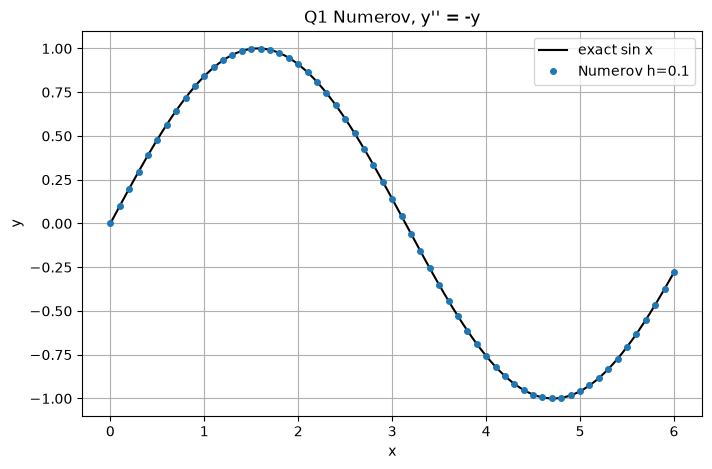

--- h = 0.05 ---
     x         y num         sin x       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.50    0.47942551    0.47942554    2.5503e-08
  1.00    0.84147094    0.84147098    4.7755e-08
  1.50    0.99749492    0.99749499    6.3568e-08
  2.00    0.90929736    0.90929743    7.0046e-08
  2.50    0.59847208    0.59847214    6.5050e-08
  3.00    0.14111996    0.14112001    4.7864e-08
  3.50   -0.35078325   -0.35078323    1.9841e-08
  4.00   -0.75680248   -0.75680250    1.5231e-08
  4.50   -0.97753007   -0.97753012    5.1298e-08
  5.00   -0.95892419   -0.95892427    8.0908e-08
  5.50   -0.70554023   -0.70554033    9.6696e-08
  6.00   -0.27941540   -0.27941550    9.3214e-08

--- h = 0.025 ---
     x         y num         sin x       |error|
  0.00    0.00000000    0.00000000    0.0000e+00
  0.50    0.47942554    0.47942554    1.5938e-09
  1.00    0.84147098    0.84147098    2.9844e-09
  1.50    0.99749498    0.99749499    3.9726e-09
  2.00    0.90929742    0.9092974

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def rk4(F, x0, u0, h, n):
    U = np.zeros((n + 1, len(u0)))
    U[0] = u0
    for i in range(n):
        x = x0 + i*h
        k1 = F(x, U[i])
        k2 = F(x + h/2, U[i] + h*k1/2)
        k3 = F(x + h/2, U[i] + h*k2/2)
        k4 = F(x + h, U[i] + h*k3)
        U[i + 1] = U[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return U


def starting_values(f, x0, y0, dy0, h, k):
    # RK4 on the system u = (y, y'), u' = (y', f(x, y)); returns y_0 ... y_k
    F = lambda x, u: np.array([u[1], f(x, u[0])])
    U = rk4(F, x0, np.array([y0, dy0], dtype=float), h, k)
    return U[:, 0]


def f(x, y):
    return -y


def numerov_linear(x0, y0, y1, h, n):
    # y'' = -y, so f_{n+1} = -y_{n+1} and the formula can be solved for y_{n+1}:
    # y_{n+1} = (2y_n - y_{n-1} + h^2/12 (10 f_n + f_{n-1})) / (1 + h^2/12)
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    y[0], y[1] = y0, y1
    F[0], F[1] = f(x[0], y[0]), f(x[1], y[1])
    for i in range(1, n):
        y[i + 1] = (2*y[i] - y[i - 1] + h*h/12*(10*F[i] + F[i - 1])) / (1 + h*h/12)
        F[i + 1] = f(x[i + 1], y[i + 1])
    return x, y


max_err = {}
for h in [0.1, 0.05, 0.025]:
    n = int(round(6/h))
    y1 = starting_values(f, 0.0, 0.0, 1.0, h, 1)[1]      # y_1 from one RK4 step
    x, y = numerov_linear(0.0, 0.0, y1, h, n)
    err = np.abs(y - np.sin(x))
    max_err[h] = err.max()

    print(f"--- h = {h} ---")
    print(f"{'x':>6}  {'y num':>12}  {'sin x':>12}  {'|error|':>12}")
    every = 1 if h == 0.1 else int(round(0.5/h))      # full table for h=0.1, every 0.5 otherwise
    for i in range(0, n + 1, every):
        print(f"{x[i]:6.2f}  {y[i]:12.8f}  {np.sin(x[i]):12.8f}  {err[i]:12.4e}")
    print()

    if h == 0.1:
        xx = np.linspace(0, 6, 400)
        plt.figure(figsize=(8, 5))
        plt.plot(xx, np.sin(xx), "k-", label="exact sin x")
        plt.plot(x, y, "o", ms=4, label="Numerov h=0.1")
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title("Q1 Numerov, y'' = -y")
        plt.legend()
        plt.grid()
        plt.show()

print(f"{'h':>8}  {'max error':>12}  {'ratio':>8}")
hs = [0.1, 0.05, 0.025]
for k in range(len(hs)):
    ratio = "" if k == 0 else f"{max_err[hs[k-1]]/max_err[hs[k]]:8.2f}"
    print(f"{hs[k]:8.3f}  {max_err[hs[k]]:12.4e}  {ratio:>8}")

print("\nstarting value y_1: one RK4 step on the system (y, y')")
print("ratio ~16 when h is halved => Numerov is 4th order")

## Q2. Numerov, nonlinear

$y''=6y^2$, $y(0)=1$, $y'(0)=-2$, exact $1/(1+x)^2$, iterate to $10^{-12}$

--- h = 0.1 ---
     x         y num         exact  iters       |error|
  0.00    1.00000000    1.00000000      -    0.0000e+00
  0.10    0.82647225    0.82644628      -    2.5969e-05
  0.20    0.69450903    0.69444444      6    6.4589e-05
  0.30    0.59182955    0.59171598      5    1.1357e-04
  0.40    0.51037731    0.51020408      5    1.7323e-04
  0.50    0.44468938    0.44444444      5    2.4494e-04
  0.60    0.39095554    0.39062500      5    3.3054e-04
  0.70    0.34645290    0.34602076      5    4.3214e-04
  0.80    0.30919398    0.30864198      5    5.5201e-04
  0.90    0.27770084    0.27700831      4    6.9253e-04
  1.00    0.25085624    0.25000000      4    8.5624e-04
max error = 8.5624e-04,  average iterations = 4.9



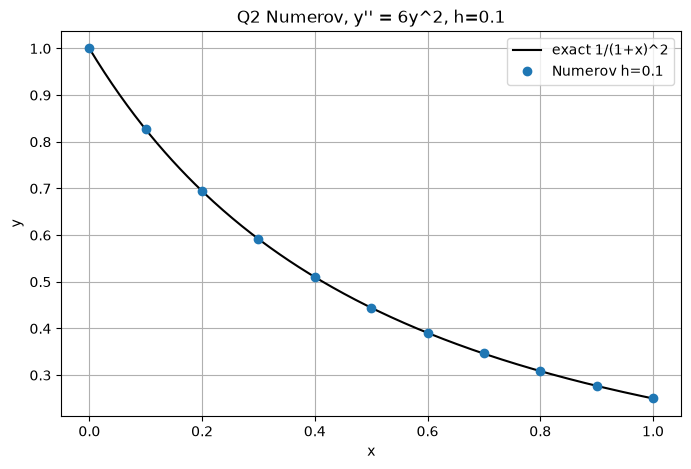

--- h = 0.05 ---
     x         y num         exact  iters       |error|
  0.00    1.00000000    1.00000000      -    0.0000e+00
  0.05    0.90703035    0.90702948      -    8.6920e-07
  0.10    0.82644827    0.82644628      4    1.9859e-06
  0.15    0.75614697    0.75614367      4    3.3059e-06
  0.20    0.69444925    0.69444444      4    4.8088e-06
  0.25    0.64000649    0.64000000      4    6.4885e-06
  0.30    0.59172432    0.59171598      4    8.3480e-06
  0.35    0.54870724    0.54869684      4    1.0396e-05
  0.40    0.51021673    0.51020408      4    1.2645e-05
  0.45    0.47563937    0.47562426      4    1.5110e-05
  0.50    0.44446225    0.44444444      4    1.7807e-05
  0.55    0.41625385    0.41623309      4    2.0755e-05
  0.60    0.39064897    0.39062500      4    2.3972e-05
  0.65    0.36733694    0.36730946      4    2.7477e-05
  0.70    0.34605205    0.34602076      4    3.1291e-05
  0.75    0.32656605    0.32653061      4    3.5435e-05
  0.80    0.30868190    0.30864

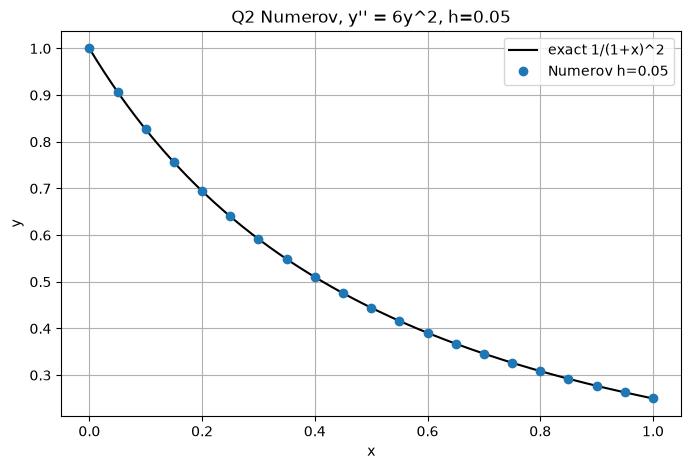

starting value y_1: one RK4 step on the system (y, y')
halving h: max error 8.6e-4 -> 6.2e-5, ratio ~14 (approaching 16, 4th order)
iterations drop too: the fixed-point factor is (h^2/12)*12y = h^2*y, so smaller h -> faster convergence


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def rk4(F, x0, u0, h, n):
    U = np.zeros((n + 1, len(u0)))
    U[0] = u0
    for i in range(n):
        x = x0 + i*h
        k1 = F(x, U[i])
        k2 = F(x + h/2, U[i] + h*k1/2)
        k3 = F(x + h/2, U[i] + h*k2/2)
        k4 = F(x + h, U[i] + h*k3)
        U[i + 1] = U[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return U


def starting_values(f, x0, y0, dy0, h, k):
    # RK4 on the system u = (y, y'), u' = (y', f(x, y)); returns y_0 ... y_k
    F = lambda x, u: np.array([u[1], f(x, u[0])])
    U = rk4(F, x0, np.array([y0, dy0], dtype=float), h, k)
    return U[:, 0]


def f(x, y):
    return 6*y**2


def exact(x):
    return 1/(1 + x)**2


def numerov(f, x0, y0, y1, h, n, tol=1e-12):
    # y_{n+1} = 2y_n - y_{n-1} + h^2/12 (f_{n+1} + 10 f_n + f_{n-1}), solved by iteration
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    iters = np.zeros(n + 1, dtype=int)
    y[0], y[1] = y0, y1
    F[0], F[1] = f(x[0], y[0]), f(x[1], y[1])
    for i in range(1, n):
        known = 2*y[i] - y[i - 1] + h*h/12*(10*F[i] + F[i - 1])
        y_old = 2*y[i] - y[i - 1] + h*h*F[i]          # first guess (explicit Stormer)
        for count in range(1, 101):
            y_new = known + h*h/12*f(x[i + 1], y_old)
            if abs(y_new - y_old) < tol:
                break
            y_old = y_new
        y[i + 1] = y_new
        F[i + 1] = f(x[i + 1], y[i + 1])
        iters[i + 1] = count
    return x, y, iters


for h in [0.1, 0.05]:
    n = int(round(1/h))
    y1 = starting_values(f, 0.0, 1.0, -2.0, h, 1)[1]
    x, y, iters = numerov(f, 0.0, 1.0, y1, h, n)
    err = np.abs(y - exact(x))

    print(f"--- h = {h} ---")
    print(f"{'x':>6}  {'y num':>12}  {'exact':>12}  {'iters':>5}  {'|error|':>12}")
    for i in range(n + 1):
        it = "-" if i < 2 else str(iters[i])
        print(f"{x[i]:6.2f}  {y[i]:12.8f}  {exact(x[i]):12.8f}  {it:>5}  {err[i]:12.4e}")
    print(f"max error = {err.max():.4e},  average iterations = {iters[2:].mean():.1f}\n")

    xx = np.linspace(0, 1, 300)
    plt.figure(figsize=(8, 5))
    plt.plot(xx, exact(xx), "k-", label="exact 1/(1+x)^2")
    plt.plot(x, y, "o", label=f"Numerov h={h}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q2 Numerov, y'' = 6y^2, h={h}")
    plt.legend()
    plt.grid()
    plt.show()

print("starting value y_1: one RK4 step on the system (y, y')")
print("halving h: max error 8.6e-4 -> 6.2e-5, ratio ~14 (approaching 16, 4th order)")
print("iterations drop too: the fixed-point factor is (h^2/12)*12y = h^2*y, so smaller h -> faster convergence")

## Q3. Störmer orders 2, 3, 4

$y_{n+1}-2y_n+y_{n-1}=h^2\left(f_n+\tfrac{1}{12}\nabla^2 f_n+\tfrac{1}{12}\nabla^3 f_n\right)$  
order 2: $h^2 f_n$  
order 3: $\frac{h^2}{12}(13f_n-2f_{n-1}+f_{n-2})$  
order 4: $\frac{h^2}{12}(14f_n-5f_{n-1}+4f_{n-2}-f_{n-3})$

--- Stormer order 2 ---
       h     max error     ratio
  0.1000    2.5194e-03          
  0.0500    6.2937e-04      4.00
  0.0250    1.5731e-04      4.00
  0.0125    3.9326e-05      4.00

--- Stormer order 3 ---
       h     max error     ratio
  0.1000    1.9349e-04          
  0.0500    2.4638e-05      7.85
  0.0250    3.1072e-06      7.93
  0.0125    3.9010e-07      7.97

--- Stormer order 4 ---
       h     max error     ratio
  0.1000    2.2817e-05          
  0.0500    1.4555e-06     15.68
  0.0250    9.1769e-08     15.86
  0.0125    5.7586e-09     15.94



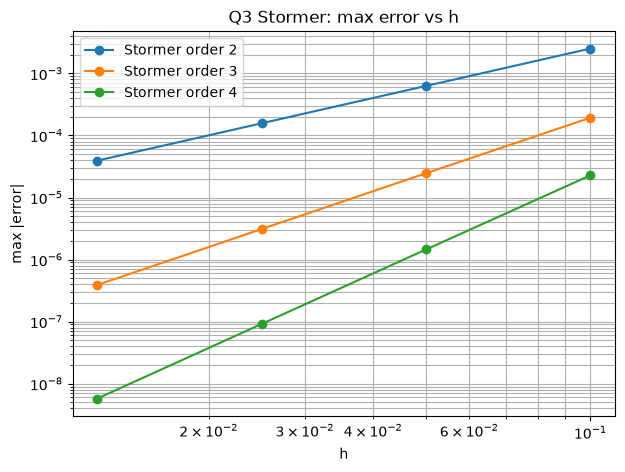

starting values: RK4 on the system (y, y')
ratios ~4, ~8, ~16 => orders 2, 3, 4 (slopes 2, 3, 4 on the log-log plot)


In [4]:
import numpy as np
import matplotlib.pyplot as plt

def rk4(F, x0, u0, h, n):
    U = np.zeros((n + 1, len(u0)))
    U[0] = u0
    for i in range(n):
        x = x0 + i*h
        k1 = F(x, U[i])
        k2 = F(x + h/2, U[i] + h*k1/2)
        k3 = F(x + h/2, U[i] + h*k2/2)
        k4 = F(x + h, U[i] + h*k3)
        U[i + 1] = U[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return U


def starting_values(f, x0, y0, dy0, h, k):
    # RK4 on the system u = (y, y'), u' = (y', f(x, y)); returns y_0 ... y_k
    F = lambda x, u: np.array([u[1], f(x, u[0])])
    U = rk4(F, x0, np.array([y0, dy0], dtype=float), h, k)
    return U[:, 0]

def stormer(f, order, x0, y_start, h, n):
    # y_{n+1} - 2y_n + y_{n-1} = h^2/12 * sum(c_j f_{n-j})
    coef = {2: [12], 3: [13, -2, 1], 4: [14, -5, 4, -1]}[order]
    k = max(len(coef), 2)            # number of starting values needed (y_0 .. y_{k-1})
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    y[:k] = y_start[:k]
    for i in range(k):
        F[i] = f(x[i], y[i])
    for i in range(k - 1, n):
        s = 0
        for j in range(len(coef)):
            s += coef[j]*F[i - j]
        y[i + 1] = 2*y[i] - y[i - 1] + h*h/12*s
        F[i + 1] = f(x[i + 1], y[i + 1])
    return x, y


def f(x, y):
    return -y


hs = [0.1, 0.05, 0.025, 0.0125]
results = {}

for order in [2, 3, 4]:
    errs = []
    for h in hs:
        n = int(round(6/h))
        y_start = starting_values(f, 0.0, 0.0, 1.0, h, 3)   # y_0..y_3 from RK4
        x, y = stormer(f, order, 0.0, y_start, h, n)
        errs.append(np.abs(y - np.sin(x)).max())
    results[order] = errs

    print(f"--- Stormer order {order} ---")
    print(f"{'h':>8}  {'max error':>12}  {'ratio':>8}")
    for k in range(len(hs)):
        ratio = "" if k == 0 else f"{errs[k-1]/errs[k]:8.2f}"
        print(f"{hs[k]:8.4f}  {errs[k]:12.4e}  {ratio:>8}")
    print()

plt.figure(figsize=(7, 5))
for order in [2, 3, 4]:
    plt.loglog(hs, results[order], "o-", label=f"Stormer order {order}")
plt.xlabel("h")
plt.ylabel("max |error|")
plt.title("Q3 Stormer: max error vs h")
plt.legend()
plt.grid(True, which="both")
plt.show()

print("starting values: RK4 on the system (y, y')")
print("ratios ~4, ~8, ~16 => orders 2, 3, 4 (slopes 2, 3, 4 on the log-log plot)")

## Q4. Pendulum

$y''=-\sin y$, $y(0)=1$, $y'(0)=0$, $0\le x\le 50$, $h=0.05$  
$E=\frac12 y'^2-\cos y$ constant

E0 = -0.5403023059

    method   |E-E0| x=10          x=25          x=50           max
 Stormer 2    2.8786e-07    2.5971e-04    1.0735e-05    2.6514e-04
 Stormer 4    4.9776e-07    3.7536e-04    1.5374e-05    3.8392e-04
       RK4    1.4438e-08    3.2163e-08    7.2947e-08    7.6786e-08


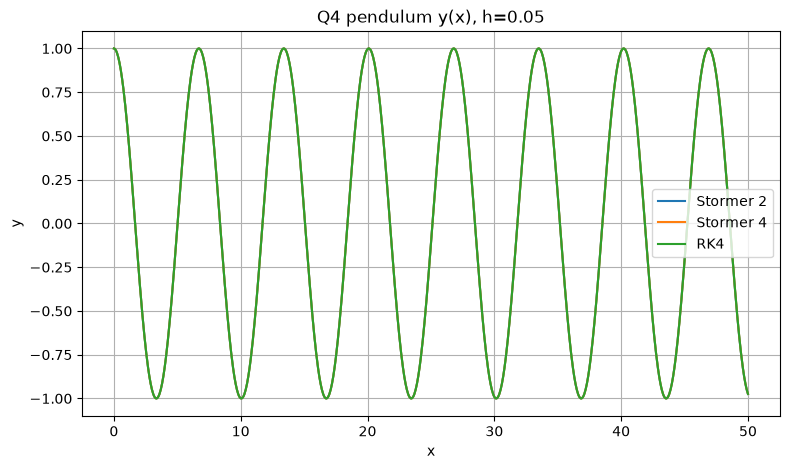

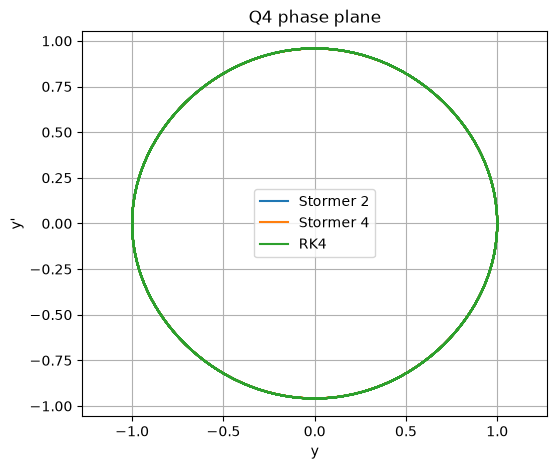

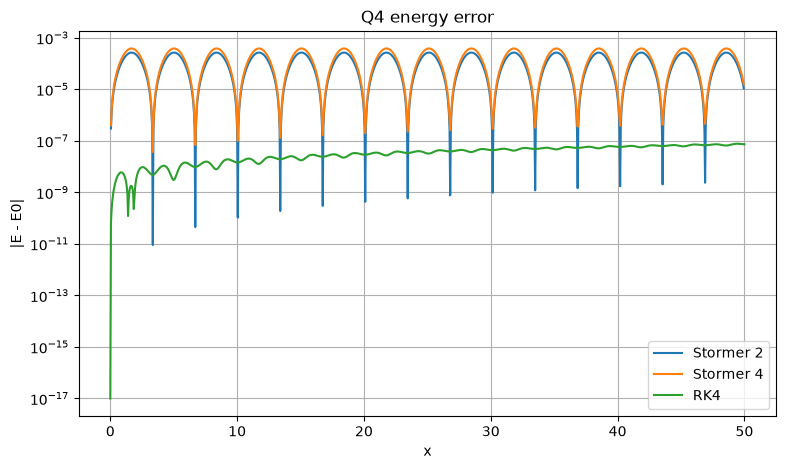

Stormer 2 and 4: |E-E0| ~1e-4, oscillates but does NOT grow over 0..50.
Both look alike because y' comes from the central difference, which is only 2nd order,
so the E error is dominated by the y' approximation, not by the method itself.
RK4: |E-E0| ~1e-8 (it computes y' directly), but it grows steadily (1.4e-8 -> 7.3e-8).
All three give the same oscillation; for long runs Stormer's bounded E error is an advantage.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

def rk4(F, x0, u0, h, n):
    U = np.zeros((n + 1, len(u0)))
    U[0] = u0
    for i in range(n):
        x = x0 + i*h
        k1 = F(x, U[i])
        k2 = F(x + h/2, U[i] + h*k1/2)
        k3 = F(x + h/2, U[i] + h*k2/2)
        k4 = F(x + h, U[i] + h*k3)
        U[i + 1] = U[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return U


def starting_values(f, x0, y0, dy0, h, k):
    # RK4 on the system u = (y, y'), u' = (y', f(x, y)); returns y_0 ... y_k
    F = lambda x, u: np.array([u[1], f(x, u[0])])
    U = rk4(F, x0, np.array([y0, dy0], dtype=float), h, k)
    return U[:, 0]

def stormer(f, order, x0, y_start, h, n):
    # y_{n+1} - 2y_n + y_{n-1} = h^2/12 * sum(c_j f_{n-j})
    coef = {2: [12], 3: [13, -2, 1], 4: [14, -5, 4, -1]}[order]
    k = max(len(coef), 2)            # number of starting values needed (y_0 .. y_{k-1})
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    y[:k] = y_start[:k]
    for i in range(k):
        F[i] = f(x[i], y[i])
    for i in range(k - 1, n):
        s = 0
        for j in range(len(coef)):
            s += coef[j]*F[i - j]
        y[i + 1] = 2*y[i] - y[i - 1] + h*h/12*s
        F[i + 1] = f(x[i + 1], y[i + 1])
    return x, y


def f(x, y):
    return -np.sin(y)


h = 0.05
n = int(round(50/h))
E0 = 0.5*0**2 - np.cos(1.0)

y_start = starting_values(f, 0.0, 1.0, 0.0, h, 3)
res = {}
for order in [2, 4]:
    x, y = stormer(f, order, 0.0, y_start, h, n)
    dy = (y[2:] - y[:-2])/(2*h)                 # central difference at x_1 .. x_{n-1}
    E = 0.5*dy**2 - np.cos(y[1:-1])
    res[f"Stormer {order}"] = (x, y, x[1:-1], dy, np.abs(E - E0))

F = lambda x, u: np.array([u[1], f(x, u[0])])
U = rk4(F, 0.0, np.array([1.0, 0.0]), h, n)
x = h*np.arange(n + 1)
E = 0.5*U[:, 1]**2 - np.cos(U[:, 0])
res["RK4"] = (x, U[:, 0], x, U[:, 1], np.abs(E - E0))

print(f"E0 = {E0:.10f}\n")
print(f"{'method':>10}  {'|E-E0| x=10':>12}  {'x=25':>12}  {'x=50':>12}  {'max':>12}")
for name, (x, y, xd, dy, dE) in res.items():
    vals = [dE[np.argmin(np.abs(xd - t))] for t in [10, 25, 50]]
    print(f"{name:>10}  {vals[0]:12.4e}  {vals[1]:12.4e}  {vals[2]:12.4e}  {dE.max():12.4e}")

plt.figure(figsize=(9, 5))
for name, (x, y, xd, dy, dE) in res.items():
    plt.plot(x, y, label=name)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Q4 pendulum y(x), h=0.05")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6, 5))
for name, (x, y, xd, dy, dE) in res.items():
    yy = y[1:-1] if name != "RK4" else y
    plt.plot(yy, dy, label=name)
plt.xlabel("y")
plt.ylabel("y'")
plt.title("Q4 phase plane")
plt.legend()
plt.grid()
plt.axis("equal")
plt.show()

plt.figure(figsize=(9, 5))
for name, (x, y, xd, dy, dE) in res.items():
    plt.semilogy(xd, dE + 1e-17, label=name)
plt.xlabel("x")
plt.ylabel("|E - E0|")
plt.title("Q4 energy error")
plt.legend()
plt.grid(True, which="both")
plt.show()

print("Stormer 2 and 4: |E-E0| ~1e-4, oscillates but does NOT grow over 0..50.")
print("Both look alike because y' comes from the central difference, which is only 2nd order,")
print("so the E error is dominated by the y' approximation, not by the method itself.")
print("RK4: |E-E0| ~1e-8 (it computes y' directly), but it grows steadily (1.4e-8 -> 7.3e-8).")
print("All three give the same oscillation; for long runs Stormer's bounded E error is an advantage.")

## Q5. Comparative study

$y''=-y$, $y(0)=1$, $y'(0)=0$, $0\le x\le 20$, exact $\cos x$

=== h = 0.1 ===
    x      Numerov    Stormer 2    Stormer 4          RK4        cos x
  0.0    1.0000000    1.0000000    1.0000000    1.0000000    1.0000000
  2.0   -0.4161472   -0.4168674   -0.4161405   -0.4161453   -0.4161468
  4.0   -0.6536430   -0.6524116   -0.6536537   -0.6536460   -0.6536436
  6.0    0.9601706    0.9608550    0.9601618    0.9601685    0.9601703
  8.0   -0.1455016   -0.1487595   -0.1454696   -0.1454934   -0.1455000
 10.0   -0.8390704   -0.8368178   -0.8390889   -0.8390755   -0.8390715
 12.0    0.8438553    0.8465071    0.8438252    0.8438479    0.8438540
 14.0    0.1367344    0.1309912    0.1367898    0.1367486    0.1367372
 16.0   -0.9576585   -0.9557289   -0.9576711   -0.9576622   -0.9576595
 18.0    0.6603195    0.6659057    0.6602596    0.6603047    0.6603167
 20.0    0.4080783    0.4004897    0.4081495    0.4080967    0.4080821

    method   f evals     max error
   Numerov       205    3.7737e-06
 Stormer 2       205    7.5923e-03
 Stormer 4       213    6.

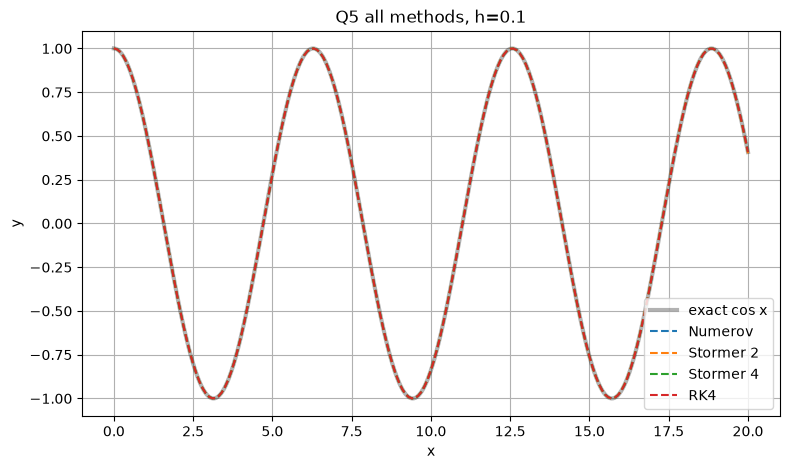

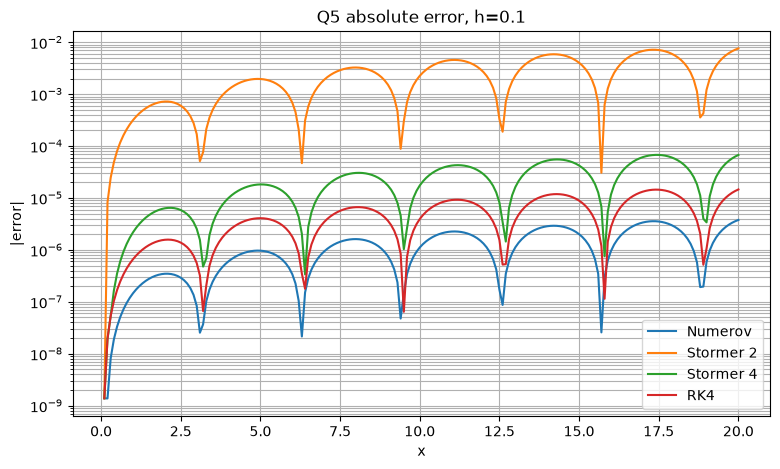

=== h = 0.05 ===
    x      Numerov    Stormer 2    Stormer 4          RK4        cos x
  0.0    1.0000000    1.0000000    1.0000000    1.0000000    1.0000000
  2.0   -0.4161469   -0.4163316   -0.4161464   -0.4161467   -0.4161468
  4.0   -0.6536436   -0.6533321   -0.6536443   -0.6536438   -0.6536436
  6.0    0.9601703    0.9603433    0.9601698    0.9601702    0.9601703
  8.0   -0.1455001   -0.1463195   -0.1454981   -0.1454996   -0.1455000
 10.0   -0.8390715   -0.8385071   -0.8390727   -0.8390718   -0.8390715
 12.0    0.8438540    0.8445214    0.8438523    0.8438536    0.8438540
 14.0    0.1367370    0.1352972    0.1367406    0.1367379    0.1367372
 16.0   -0.9576594   -0.9571797   -0.9576604   -0.9576597   -0.9576595
 18.0    0.6603169    0.6617201    0.6603132    0.6603160    0.6603167
 20.0    0.4080818    0.4061834    0.4080864    0.4080830    0.4080821

    method   f evals     max error
   Numerov       405    2.3678e-07
 Stormer 2       405    1.8986e-03
 Stormer 4       413    4

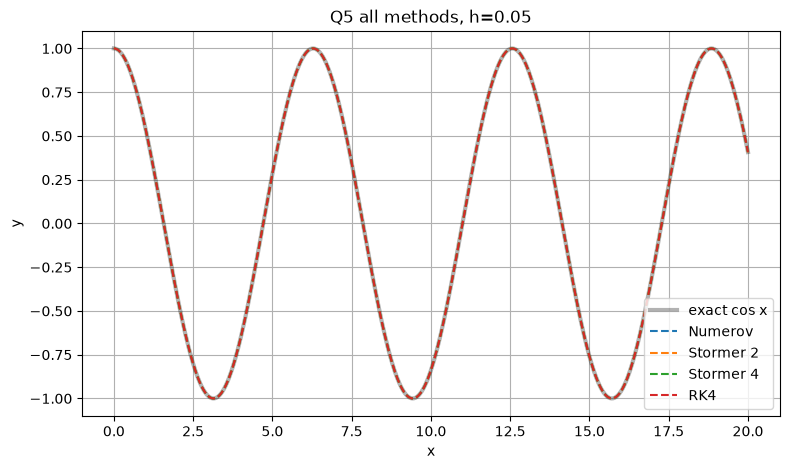

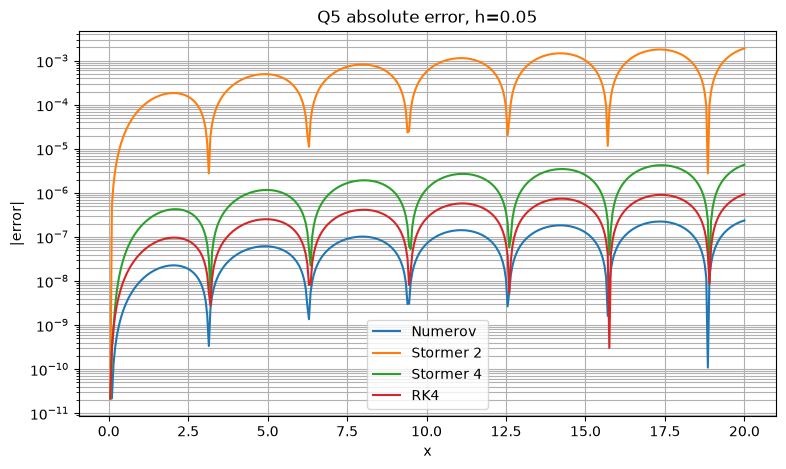

f evals include the RK4 starting steps (4 evals each).
best at a given h: Numerov, then RK4, Stormer 4, Stormer 2.
best for given work: Numerov (1 eval/step). With ~200 evals Numerov has err 3.8e-6,
RK4 needs 800 evals for 1.5e-5. Stormer 4 with 413 evals (h=0.05) also beats RK4 with 800.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def rk4(F, x0, u0, h, n):
    U = np.zeros((n + 1, len(u0)))
    U[0] = u0
    for i in range(n):
        x = x0 + i*h
        k1 = F(x, U[i])
        k2 = F(x + h/2, U[i] + h*k1/2)
        k3 = F(x + h/2, U[i] + h*k2/2)
        k4 = F(x + h, U[i] + h*k3)
        U[i + 1] = U[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return U


def starting_values(f, x0, y0, dy0, h, k):
    # RK4 on the system u = (y, y'), u' = (y', f(x, y)); returns y_0 ... y_k
    F = lambda x, u: np.array([u[1], f(x, u[0])])
    U = rk4(F, x0, np.array([y0, dy0], dtype=float), h, k)
    return U[:, 0]

def stormer(f, order, x0, y_start, h, n):
    # y_{n+1} - 2y_n + y_{n-1} = h^2/12 * sum(c_j f_{n-j})
    coef = {2: [12], 3: [13, -2, 1], 4: [14, -5, 4, -1]}[order]
    k = max(len(coef), 2)            # number of starting values needed (y_0 .. y_{k-1})
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    y[:k] = y_start[:k]
    for i in range(k):
        F[i] = f(x[i], y[i])
    for i in range(k - 1, n):
        s = 0
        for j in range(len(coef)):
            s += coef[j]*F[i - j]
        y[i + 1] = 2*y[i] - y[i - 1] + h*h/12*s
        F[i + 1] = f(x[i + 1], y[i + 1])
    return x, y


count = [0]


def f(x, y):
    count[0] += 1
    return -y


def numerov_linear(x0, y0, y1, h, n):
    x = x0 + h*np.arange(n + 1)
    y = np.zeros(n + 1)
    F = np.zeros(n + 1)
    y[0], y[1] = y0, y1
    F[0], F[1] = f(x[0], y[0]), f(x[1], y[1])
    for i in range(1, n):
        y[i + 1] = (2*y[i] - y[i - 1] + h*h/12*(10*F[i] + F[i - 1])) / (1 + h*h/12)
        F[i + 1] = f(x[i + 1], y[i + 1])
    return x, y


for h in [0.1, 0.05]:
    n = int(round(20/h))
    out = {}

    count[0] = 0
    y_start = starting_values(f, 0.0, 1.0, 0.0, h, 1)
    x, y = numerov_linear(0.0, 1.0, y_start[1], h, n)
    out["Numerov"] = (y, count[0])

    for order in [2, 4]:
        count[0] = 0
        y_start = starting_values(f, 0.0, 1.0, 0.0, h, order - 1)
        x, y = stormer(f, order, 0.0, y_start, h, n)
        out[f"Stormer {order}"] = (y, count[0])

    count[0] = 0
    U = rk4(lambda x, u: np.array([u[1], f(x, u[0])]), 0.0, np.array([1.0, 0.0]), h, n)
    out["RK4"] = (U[:, 0], count[0])

    print(f"=== h = {h} ===")
    print(f"{'x':>5}" + "".join(f"  {name:>11}" for name in out) + f"  {'cos x':>11}")
    for i in range(0, n + 1, int(round(2/h))):
        print(f"{x[i]:5.1f}" + "".join(f"  {out[m][0][i]:11.7f}" for m in out) + f"  {np.cos(x[i]):11.7f}")

    print(f"\n{'method':>10}  {'f evals':>8}  {'max error':>12}")
    for name, (y, ev) in out.items():
        print(f"{name:>10}  {ev:8d}  {np.abs(y - np.cos(x)).max():12.4e}")
    print()

    xx = np.linspace(0, 20, 800)
    plt.figure(figsize=(9, 5))
    plt.plot(xx, np.cos(xx), "k-", lw=3, alpha=0.3, label="exact cos x")
    for name, (y, ev) in out.items():
        plt.plot(x, y, "--", label=name)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"Q5 all methods, h={h}")
    plt.legend()
    plt.grid()
    plt.show()

    plt.figure(figsize=(9, 5))
    for name, (y, ev) in out.items():
        plt.semilogy(x[1:], np.abs(y[1:] - np.cos(x[1:])), label=name)
    plt.xlabel("x")
    plt.ylabel("|error|")
    plt.title(f"Q5 absolute error, h={h}")
    plt.legend()
    plt.grid(True, which="both")
    plt.show()

print("f evals include the RK4 starting steps (4 evals each).")
print("best at a given h: Numerov, then RK4, Stormer 4, Stormer 2.")
print("best for given work: Numerov (1 eval/step). With ~200 evals Numerov has err 3.8e-6,")
print("RK4 needs 800 evals for 1.5e-5. Stormer 4 with 413 evals (h=0.05) also beats RK4 with 800.")